# Fine-tuning Stable Diffusion v1.5 on COCO — Milestone 1 pilot (LoRA)

**Author:** Mukul Sridar Haladhi

**Research question (whole project):** *How much of Stable Diffusion do you need to train?*
Compare fine-tuning methods (LoRA → cross-attention-only → full UNet) on the same COCO data, measuring
quality, prompt-following, trainable parameters, GPU memory and training time.

**This notebook (Milestone 1):** the training setup plus one LoRA pilot run.

| Step | What |
|---|---|
| 1 | Environment + config (one place for every knob) |
| 2 | Data: ~3,000 COCO **train2017** pairs for training; COCO **val2017** for evaluation only, so nothing leaks into the team's val-based experiments |
| 3 | Cache VAE latents (+ horizontally flipped copies) once, so training only runs the UNet |
| 4 | Model + trainable-parameter setup (`METHOD = "lora"`; `"attn_only"` / `"full"` ready for Milestone 2) |
| 5 | Training loop: ε-prediction MSE, AdamW, cosine LR, fp16 autocast + GradScaler, caption dropout |
| 6 | Held-out **validation diffusion loss** (fixed noise, fixed timesteps) at every checkpoint |
| 7 | Base vs. fine-tuned: CLIPScore on 40 held-out prompts (paired, with a bootstrap CI) + 5 showcase prompts |
| 8 | Save metrics for the Milestone 2 comparison table |

Designed for a **Colab T4 (16 GB)**: runtime → change runtime type → T4 GPU. Full run ≈ 45–60 min.

## 1. Environment & config

In [ ]:
   %pip uninstall -y -q torchao
   %pip install -q "diffusers>=0.30" "transformers>=4.44" "peft>=0.12" accelerate safetensors

In [ ]:
import os, re, json, math, time, random, zipfile, textwrap, unicodedata, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4 or better)."
DEVICE = "cuda"
print(torch.__version__, torch.cuda.get_device_name(0),
      f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

CFG = dict(
    # --- run ---
    run_name="lora_r8_pilot",
    method="lora",              # "lora" | "attn_only" | "full"  (full needs >24 GB; Milestone 2)
    seed=42,
    # --- data ---
    n_train=3000,               # within the milestone's 1k–5k
    n_val_loss=100,             # held-out val2017 images for the validation diffusion loss
    n_eval_prompts=40,          # held-out val2017 captions for CLIPScore
    n_showcase=5,               # the 5 prompt->image test runs
    resolution=512,
    min_side=384, max_aspect=2.0,
    min_words=5, max_words=40,
    # --- model ---
    sd_model="stable-diffusion-v1-5/stable-diffusion-v1-5",
    clip_model="openai/clip-vit-large-patch14",   # same CLIP the rest of the team scores with
    lora_rank=8, lora_alpha=8,
    lora_targets=["to_q", "to_k", "to_v", "to_out.0"],   # every attention projection in the UNet
    # --- optimisation ---
    max_steps=600,              # pilot length; Milestone 2 runs go longer
    batch_size=2, grad_accum=2, # effective batch 4
    lr=1e-4, lr_warmup=50, weight_decay=1e-2, max_grad_norm=1.0,
    caption_dropout=0.10,       # keep classifier-free guidance working after fine-tuning
    gradient_checkpointing=True,
    eval_every=150,             # val loss + LoRA checkpoint every N optimiser steps
    # --- sampling for evaluation ---
    sample_steps=25, guidance=7.5,
)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["seed"])

ROOT = Path("/content/ft_data") if Path("/content").exists() else Path("./ft_data").resolve()
RAW, IMG_TR, IMG_VA = ROOT/"raw", ROOT/"train_images", ROOT/"val_images"
RUN = ROOT/"runs"/CFG["run_name"]
for d in (RAW, IMG_TR, IMG_VA, RUN/"checkpoints", RUN/"samples"):
    d.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(RUN/"config.json", "w"), indent=2)
print("run dir:", RUN)

2.11.0+cu130 Tesla T4 15.6 GB
run dir: /content/ft_data/runs/lora_r8_pilot


## 2. Data
Captions and image metadata come from the COCO 2017 annotation zip (~240 MB). Only the images we use are
downloaded, one by one, from `coco_url`, so we never pull the 18 GB train zip.

* **Train:** `n_train` images from **train2017** that pass cheap metadata rules (short side ≥ 384 px, aspect ≤ 2, 5 captions).
  All of an image's clean captions are kept; one is sampled at random every time the image is drawn, which acts as text augmentation.
* **Eval:** disjoint images from **val2017**: 100 for validation loss, 40 captions for CLIPScore, 5 showcase pairs.

In [ ]:
ANN_ZIP = RAW/"annotations_trainval2017.zip"
if not (RAW/"annotations"/"captions_train2017.json").exists():
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ANN_ZIP)
    with zipfile.ZipFile(ANN_ZIP) as z:
        for m in ("annotations/captions_train2017.json", "annotations/captions_val2017.json"):
            z.extract(m, RAW)
    ANN_ZIP.unlink()

def load_split(name):
    d = json.load(open(RAW/"annotations"/f"captions_{name}.json"))
    ims = pd.DataFrame(d["images"])[["id", "file_name", "coco_url", "height", "width"]].rename(columns={"id": "image_id"})
    caps = pd.DataFrame(d["annotations"])[["image_id", "caption"]]
    return ims, caps

def clean_caption(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = re.sub(r"\s+", " ", t).strip()
    t = re.sub(r"\s+([.,!?;:])", r"\1", t)
    t = re.sub(r"\b(\w+) \1\b", r"\1", t, flags=re.I)       # "a a dog" -> "a dog"
    return t.rstrip(" .").strip()

def prepare(ims, caps):
    caps = caps.copy()
    caps["clean"] = caps.caption.map(clean_caption)
    n = caps.clean.str.split().str.len()
    caps = caps[n.between(CFG["min_words"], CFG["max_words"])].drop_duplicates(["image_id", "clean"])
    grouped = caps.groupby("image_id").clean.apply(list)
    ims = ims.assign(min_side=ims[["height", "width"]].min(1),
                     aspect=ims[["height", "width"]].max(1) / ims[["height", "width"]].min(1))
    ims = ims[(ims.min_side >= CFG["min_side"]) & (ims.aspect <= CFG["max_aspect"])]
    ims = ims[ims.image_id.isin(grouped.index)].copy()
    ims["captions"] = ims.image_id.map(grouped)
    return ims[ims.captions.str.len() >= 3].reset_index(drop=True)

tr_ims, tr_caps = load_split("train2017")
va_ims, va_caps = load_split("val2017")
tr_pool, va_pool = prepare(tr_ims, tr_caps), prepare(va_ims, va_caps)
print(f"eligible train images: {len(tr_pool):,} | eligible val images: {len(va_pool):,}")

train_df = tr_pool.sample(int(CFG["n_train"] * 1.05), random_state=CFG["seed"]).reset_index(drop=True)  # 5% spare for failed downloads
va_shuf  = va_pool.sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
k1, k2 = CFG["n_val_loss"], CFG["n_val_loss"] + CFG["n_showcase"]
valloss_df   = va_shuf.iloc[:k1].reset_index(drop=True)
showcase_df  = va_shuf.iloc[k1:k2].reset_index(drop=True)
evalprom_df  = va_shuf.iloc[k2:k2 + CFG["n_eval_prompts"]].reset_index(drop=True)

eligible train images: 97,799 | eligible val images: 4,072


In [ ]:
def fetch(row, folder):
    dst = folder/row.file_name
    if dst.exists() and dst.stat().st_size > 0:
        return True
    for attempt in range(3):
        try:
            r = requests.get(row.coco_url, timeout=30); r.raise_for_status()
            dst.write_bytes(r.content); return True
        except Exception:
            time.sleep(1 + attempt)
    return False

def fetch_all(df, folder, desc):
    with ThreadPoolExecutor(16) as ex:
        ok = list(tqdm(ex.map(lambda r: fetch(r, folder), df.itertuples()), total=len(df), desc=desc))
    df = df[ok].reset_index(drop=True)
    df["path"] = [str(folder/f) for f in df.file_name]
    return df

train_df    = fetch_all(train_df, IMG_TR, "train images").iloc[:CFG["n_train"]].reset_index(drop=True)
valloss_df  = fetch_all(valloss_df, IMG_VA, "val images")
showcase_df = fetch_all(showcase_df, IMG_VA, "showcase images")
print(f"train pairs: {len(train_df)} images / {train_df.captions.str.len().sum():,} captions | "
      f"val-loss images: {len(valloss_df)} | showcase: {len(showcase_df)} | eval prompts: {len(evalprom_df)}")

train images:   0%|          | 0/3150 [00:00<?, ?it/s]

val images:   0%|          | 0/100 [00:00<?, ?it/s]

showcase images:   0%|          | 0/5 [00:00<?, ?it/s]

train pairs: 3000 images / 15,004 captions | val-loss images: 100 | showcase: 5 | eval prompts: 40


## 3. Cache VAE latents
The VAE is frozen, so encoding every image once (and its horizontal flip, as augmentation) turns each
training step into a UNet-only forward/backward. 3,000 images × 2 × `[4, 64, 64]` in fp16 ≈ 100 MB.
Images that fail to open or aren't usable are dropped here.

In [ ]:
from diffusers import AutoencoderKL
vae = AutoencoderKL.from_pretrained(CFG["sd_model"], subfolder="vae", torch_dtype=torch.float16).to(DEVICE).eval()
SCALE = vae.config.scaling_factor            # 0.18215 for SD v1.5

def load_square(path, size=CFG["resolution"]):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        w, h = im.size; s = size / min(w, h)
        im = im.resize((max(size, round(w*s)), max(size, round(h*s))), Image.Resampling.LANCZOS)
        w, h = im.size; l, t = (w - size)//2, (h - size)//2
        return im.crop((l, t, l + size, t + size))

def to_tensor(im):
    x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 127.5 - 1.0)
    return x.permute(2, 0, 1)

@torch.no_grad()
def cache_latents(df, flips=True, bs=16, desc="latents"):
    lat, lat_f, keep = [], [], []
    for i in tqdm(range(0, len(df), bs), desc=desc):
        xs, ok = [], []
        for j, p in enumerate(df.path.iloc[i:i+bs]):
            try:
                xs.append(to_tensor(load_square(p))); ok.append(i + j)
            except Exception:
                pass
        if not xs: continue
        x = torch.stack(xs).to(DEVICE, torch.float16)
        lat.append((vae.encode(x).latent_dist.sample() * SCALE).cpu())
        if flips:
            lat_f.append((vae.encode(torch.flip(x, dims=[3])).latent_dist.sample() * SCALE).cpu())
        keep += ok
    out = {"lat": torch.cat(lat)}
    if flips: out["lat_flip"] = torch.cat(lat_f)
    return out, df.iloc[keep].reset_index(drop=True)

TRAIN_LAT, train_df = cache_latents(train_df, desc="train latents")
VAL_LAT, valloss_df = cache_latents(valloss_df, flips=False, desc="val latents")
torch.save({"train": TRAIN_LAT, "val": VAL_LAT}, ROOT/"latents.pt")
print("train latents:", tuple(TRAIN_LAT["lat"].shape), "| val latents:", tuple(VAL_LAT["lat"].shape))

del vae; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

train latents:   0%|          | 0/188 [00:00<?, ?it/s]

val latents:   0%|          | 0/7 [00:00<?, ?it/s]

train latents: (3000, 4, 64, 64) | val latents: (100, 4, 64, 64)


## 4. Model and trainable parameters
Everything is loaded in fp16 and frozen. `setup_trainable` then decides what learns:

| `method` | What trains | Notes |
|---|---|---|
| `lora` | rank-*r* adapters on every attention projection (`to_q/k/v/out`) | this pilot |
| `attn_only` | the full weights of the 16 cross-attention (`attn2`) layers, the only layers that read the text | Milestone 2 |
| `full` | the whole UNet (~860 M params) | Milestone 2, needs >24 GB or 8-bit Adam |

Trainable parameters are cast to **fp32** (the frozen ones stay fp16); fp16 autocast + `GradScaler` handle the forward/backward.

In [ ]:
from transformers import CLIPTokenizer, CLIPTextModel
from diffusers import UNet2DConditionModel, DDPMScheduler
from diffusers.training_utils import cast_training_params
from diffusers.optimization import get_scheduler
from peft import LoraConfig

tokenizer    = CLIPTokenizer.from_pretrained(CFG["sd_model"], subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(CFG["sd_model"], subfolder="text_encoder", torch_dtype=torch.float16).to(DEVICE).eval()
noise_sched  = DDPMScheduler.from_pretrained(CFG["sd_model"], subfolder="scheduler")
unet         = UNet2DConditionModel.from_pretrained(CFG["sd_model"], subfolder="unet", torch_dtype=torch.float16).to(DEVICE)
text_encoder.requires_grad_(False)
assert noise_sched.config.prediction_type == "epsilon"

def setup_trainable(unet, method):
    unet.requires_grad_(False)
    if method == "lora":
        unet.add_adapter(LoraConfig(r=CFG["lora_rank"], lora_alpha=CFG["lora_alpha"],
                                    init_lora_weights="gaussian", target_modules=CFG["lora_targets"]))
    elif method == "attn_only":
        for n, p in unet.named_parameters():
            if ".attn2." in n: p.requires_grad_(True)
    elif method == "full":
        unet.requires_grad_(True)
    else:
        raise ValueError(method)
    cast_training_params(unet, dtype=torch.float32)
    return [p for p in unet.parameters() if p.requires_grad]

params = setup_trainable(unet, CFG["method"])
if CFG["gradient_checkpointing"]:
    unet.enable_gradient_checkpointing()

n_train_p = sum(p.numel() for p in params)
n_total_p = sum(p.numel() for p in unet.parameters())
PARAM_INFO = {"trainable_params": n_train_p, "total_unet_params": n_total_p,
              "trainable_pct": round(100 * n_train_p / n_total_p, 3)}
print(f"{CFG['method']}: {n_train_p/1e6:.2f} M trainable of {n_total_p/1e6:.1f} M ({PARAM_INFO['trainable_pct']}%)")

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (3 outputs left out)

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

lora: 1.59 M trainable of 861.1 M (0.185%)


In [ ]:
@torch.no_grad()
def encode_text(texts):
    ids = tokenizer(texts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    return text_encoder(ids)[0]              # [B, 77, 768], exactly what the SD pipeline feeds the UNet

# Fixed validation set: same latents, noise, timesteps and captions every time -> differences are the model's.
g = torch.Generator().manual_seed(1234)
VAL_REPEATS = 2
V_lat   = VAL_LAT["lat"].repeat(VAL_REPEATS, 1, 1, 1)
V_noise = torch.randn(V_lat.shape, generator=g)
V_t     = torch.linspace(20, noise_sched.config.num_train_timesteps - 20, len(V_lat)).long()[torch.randperm(len(V_lat), generator=g)]
V_caps  = [c[0] for c in valloss_df.captions] * VAL_REPEATS

@torch.no_grad()
def validation_loss(bs=8):
    unet.eval(); tot, n = 0.0, 0
    for i in range(0, len(V_lat), bs):
        lat, noise, t = V_lat[i:i+bs].to(DEVICE), V_noise[i:i+bs].to(DEVICE), V_t[i:i+bs].to(DEVICE)
        noisy = noise_sched.add_noise(lat.float(), noise, t).half()
        with torch.autocast("cuda", dtype=torch.float16):
            pred = unet(noisy, t, encoder_hidden_states=encode_text(V_caps[i:i+bs])).sample
        tot += F.mse_loss(pred.float(), noise, reduction="sum").item(); n += noise.numel()
    unet.train()
    return tot / n

def save_checkpoint(step):
    path = RUN/"checkpoints"/f"step_{step:05d}"
    path.mkdir(parents=True, exist_ok=True)
    if CFG["method"] == "lora":
        from peft.utils import get_peft_model_state_dict
        from diffusers.utils import convert_state_dict_to_diffusers
        from diffusers import StableDiffusionPipeline
        sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
        StableDiffusionPipeline.save_lora_weights(save_directory=str(path), unet_lora_layers=sd, safe_serialization=True)
    else:
        torch.save({n: p.detach().half().cpu() for n, p in unet.named_parameters() if p.requires_grad},
                   path/"trainable_weights.pt")
    return path

base_val = validation_loss()
print(f"validation loss of the untouched base model: {base_val:.5f}")

validation loss of the untouched base model: 0.15120


## 5. Training loop
Standard latent-diffusion objective: sample a timestep *t*, add noise to the latent, and train the UNet to
predict that noise (ε-prediction, MSE). 10% of captions are replaced with `""` so the model keeps an
unconditional branch for classifier-free guidance.

In [ ]:
optimizer = torch.optim.AdamW(params, lr=CFG["lr"], weight_decay=CFG["weight_decay"])
lr_sched  = get_scheduler("cosine", optimizer, num_warmup_steps=CFG["lr_warmup"], num_training_steps=CFG["max_steps"])
scaler    = torch.amp.GradScaler("cuda")

N, B = len(train_df), CFG["batch_size"]
captions = train_df.captions.tolist()
T = noise_sched.config.num_train_timesteps
log, val_log, ckpts = [], [{"step": 0, "val_loss": base_val}], {}

unet.train()
torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
t_start = time.time()
pbar = tqdm(range(1, CFG["max_steps"] + 1), desc="training")
for step in pbar:
    step_loss = 0.0
    for _ in range(CFG["grad_accum"]):
        idx  = torch.randint(0, N, (B,))
        flip = torch.rand(B) < 0.5
        lat  = torch.where(flip[:, None, None, None], TRAIN_LAT["lat_flip"][idx], TRAIN_LAT["lat"][idx]).to(DEVICE).float()
        caps = ["" if random.random() < CFG["caption_dropout"] else random.choice(captions[i]) for i in idx.tolist()]

        noise = torch.randn_like(lat)
        t     = torch.randint(0, T, (B,), device=DEVICE).long()
        noisy = noise_sched.add_noise(lat, noise, t).half()
        with torch.autocast("cuda", dtype=torch.float16):
            pred = unet(noisy, t, encoder_hidden_states=encode_text(caps)).sample
        loss = F.mse_loss(pred.float(), noise) / CFG["grad_accum"]
        scaler.scale(loss).backward()
        step_loss += loss.item()

    scaler.unscale_(optimizer)
    gnorm = torch.nn.utils.clip_grad_norm_(params, CFG["max_grad_norm"]).item()
    scaler.step(optimizer); scaler.update()
    optimizer.zero_grad(set_to_none=True); lr_sched.step()

    log.append({"step": step, "loss": step_loss, "lr": lr_sched.get_last_lr()[0], "grad_norm": gnorm})
    pbar.set_postfix(loss=f"{step_loss:.4f}")

    if step % CFG["eval_every"] == 0 or step == CFG["max_steps"]:
        v = validation_loss()
        val_log.append({"step": step, "val_loss": v})
        ckpts[step] = save_checkpoint(step)
        print(f"step {step}: train loss (last 50) {np.mean([r['loss'] for r in log[-50:]]):.4f} | val loss {v:.5f}")

torch.cuda.synchronize()
TRAIN_INFO = {"train_minutes": round((time.time() - t_start) / 60, 1),
              "sec_per_step": round((time.time() - t_start) / CFG["max_steps"], 3),
              "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
              "images_seen": CFG["max_steps"] * B * CFG["grad_accum"]}
pd.DataFrame(log).to_csv(RUN/"train_log.csv", index=False)
pd.DataFrame(val_log).to_csv(RUN/"val_log.csv", index=False)
print(TRAIN_INFO)

training:   0%|          | 0/600 [00:00<?, ?it/s]

step 150: train loss (last 50) 0.1392 | val loss 0.15107
step 300: train loss (last 50) 0.1595 | val loss 0.15106
step 450: train loss (last 50) 0.1617 | val loss 0.15103
step 600: train loss (last 50) 0.1706 | val loss 0.15102
{'train_minutes': 13.8, 'sec_per_step': 1.379, 'peak_gpu_gb': 2.59, 'images_seen': 2400}


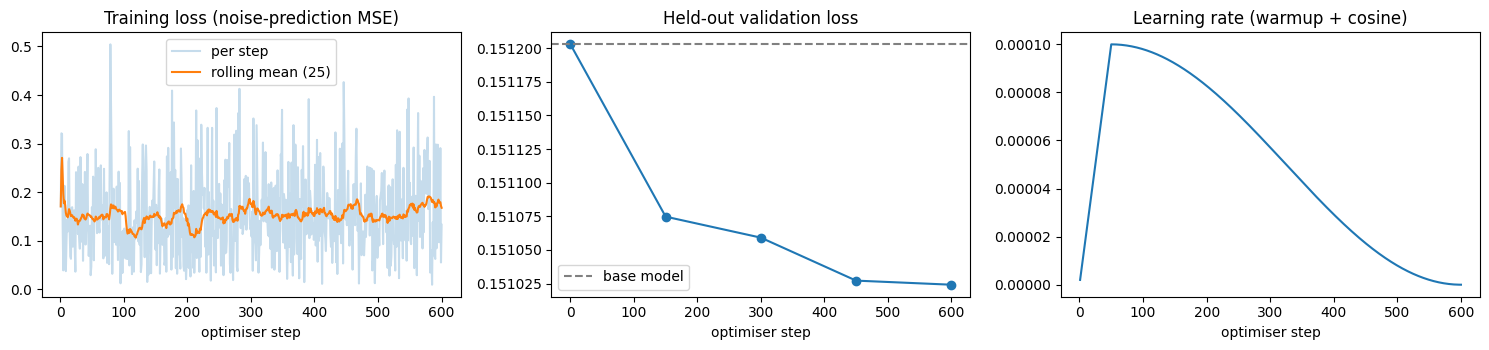

In [ ]:
lg, vl = pd.DataFrame(log), pd.DataFrame(val_log)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(lg.step, lg.loss, alpha=.25, label="per step")
ax[0].plot(lg.step, lg.loss.rolling(25, min_periods=1).mean(), label="rolling mean (25)")
ax[0].set(title="Training loss (noise-prediction MSE)", xlabel="optimiser step"); ax[0].legend()
ax[1].plot(vl.step, vl.val_loss, "o-"); ax[1].axhline(base_val, ls="--", c="gray", label="base model")
ax[1].set(title="Held-out validation loss", xlabel="optimiser step"); ax[1].legend()
ax[2].plot(lg.step, lg.lr); ax[2].set(title="Learning rate (warmup + cosine)", xlabel="optimiser step")
plt.tight_layout(); plt.savefig(RUN/"curves.png", dpi=150); plt.show()

## 6. Evaluation: base vs. fine-tuned
The training UNet is freed, and a fresh SD v1.5 pipeline is loaded. Every checkpoint is applied to it in turn, and
**the same prompts and the same seeds** are generated for the base model and each checkpoint, so every comparison is paired.

* **CLIPScore** = 100 × max(cos(image, caption), 0) with CLIP ViT-L/14, on 40 held-out val2017 captions.
* A **paired bootstrap** gives a 95% interval for (fine-tuned − base).
* Images blacked out by the safety checker are excluded pairwise.

COCO photos are everyday snapshots, so fine-tuning may move the *style* toward COCO and away from SD's polished look,
even if prompt-following improves. Both effects are what we're measuring.

In [ ]:
del unet, optimizer, params, scaler; torch.cuda.empty_cache()

from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from transformers import CLIPModel, CLIPProcessor

pipe = StableDiffusionPipeline.from_pretrained(CFG["sd_model"], torch_dtype=torch.float16).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

clip = CLIPModel.from_pretrained(CFG["clip_model"], torch_dtype=torch.float16).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG["clip_model"])

@torch.no_grad()
def clipscore(images, texts):
    x = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE, torch.float16)
    tk = clip_proc(text=texts, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    i = F.normalize(clip.get_image_features(pixel_values=x).float(), dim=-1)
    t = F.normalize(clip.get_text_features(**tk).float(), dim=-1)
    return (100 * (i * t).sum(-1).clamp(min=0)).cpu().numpy()

BASE_ATTN = None
def apply_checkpoint(path):
    global BASE_ATTN
    if CFG["method"] == "lora":
        pipe.unload_lora_weights()
        if path is not None: pipe.load_lora_weights(str(path))
    else:
        if BASE_ATTN is None:
            BASE_ATTN = {n: p.detach().clone() for n, p in pipe.unet.named_parameters()
                         if CFG["method"] == "full" or ".attn2." in n}
        pipe.unet.load_state_dict(BASE_ATTN, strict=False)
        if path is not None:
            pipe.unet.load_state_dict(torch.load(path/"trainable_weights.pt"), strict=False)

@torch.no_grad()
def generate(prompts, seed0=0, bs=4):
    imgs, flagged = [], []
    for i in range(0, len(prompts), bs):
        gens = [torch.Generator("cpu").manual_seed(seed0 + i + k) for k in range(len(prompts[i:i+bs]))]
        out = pipe(prompts[i:i+bs], num_inference_steps=CFG["sample_steps"], guidance_scale=CFG["guidance"], generator=gens)
        imgs += out.images
        flagged += list(out.nsfw_content_detected) if out.nsfw_content_detected is not None else [False] * len(out.images)
    return imgs, flagged

EVAL_PROMPTS = [c[0] for c in evalprom_df.captions]
SHOW_PROMPTS = [c[0] for c in showcase_df.captions]
models = {"base": None, **{f"step_{s}": p for s, p in ckpts.items()}}

scores, flags, show_imgs = {}, {}, {}
for name, path in models.items():
    apply_checkpoint(path)
    imgs, fl = generate(EVAL_PROMPTS, seed0=0)
    scores[name], flags[name] = clipscore(imgs, EVAL_PROMPTS), np.array(fl)
    show_imgs[name], _ = generate(SHOW_PROMPTS, seed0=10_000)
    for k, im in enumerate(show_imgs[name]):
        im.save(RUN/"samples"/f"{name}_showcase_{k+1}.png")
    print(f"{name:>12}: CLIPScore {scores[name].mean():.2f}  (safety-flagged {int(sum(fl))})")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

        base: CLIPScore 25.52  (safety-flagged 0)


... (4 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


    step_450: CLIPScore 26.29  (safety-flagged 0)


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


    step_600: CLIPScore 26.37  (safety-flagged 0)


In [ ]:
def paired_bootstrap(a, b, n=5000, seed=0):
    d = b - a; rng = np.random.default_rng(seed)
    boots = rng.choice(d, (n, len(d)), replace=True).mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

rows = []
for name in models:
    keep = ~(flags["base"] | flags[name])
    mean_d, lo, hi = paired_bootstrap(scores["base"][keep], scores[name][keep]) if name != "base" else (0, 0, 0)
    step = 0 if name == "base" else int(name.split("_")[1])
    rows.append({"model": name, "step": step,
                 "clipscore_mean": round(float(scores[name][keep].mean()), 2),
                 "delta_vs_base": round(float(mean_d), 2), "ci95_low": round(float(lo), 2), "ci95_high": round(float(hi), 2),
                 "win_rate_vs_base": round(float((scores[name][keep] > scores["base"][keep]).mean()), 2) if name != "base" else None,
                 "val_loss": next(v["val_loss"] for v in val_log if v["step"] == step),
                 "n_pairs": int(keep.sum())})
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(RUN/"eval_results.csv", index=False)
RESULTS

,model,step,clipscore_mean,delta_vs_base,ci95_low,ci95_high,win_rate_vs_base,val_loss,n_pairs
0,base,0,25.52,0.00,0.00,0.00,NaN,0.151203,40
1,step_150,150,25.96,0.44,-0.11,1.01,0.50,0.151075,40
2,step_300,300,26.28,0.75,0.14,1.38,0.62,0.151059,40
3,step_450,450,26.29,0.77,0.16,1.40,0.65,0.151027,40
4,step_600,600,26.37,0.84,0.16,1.53,0.72,0.151024,40


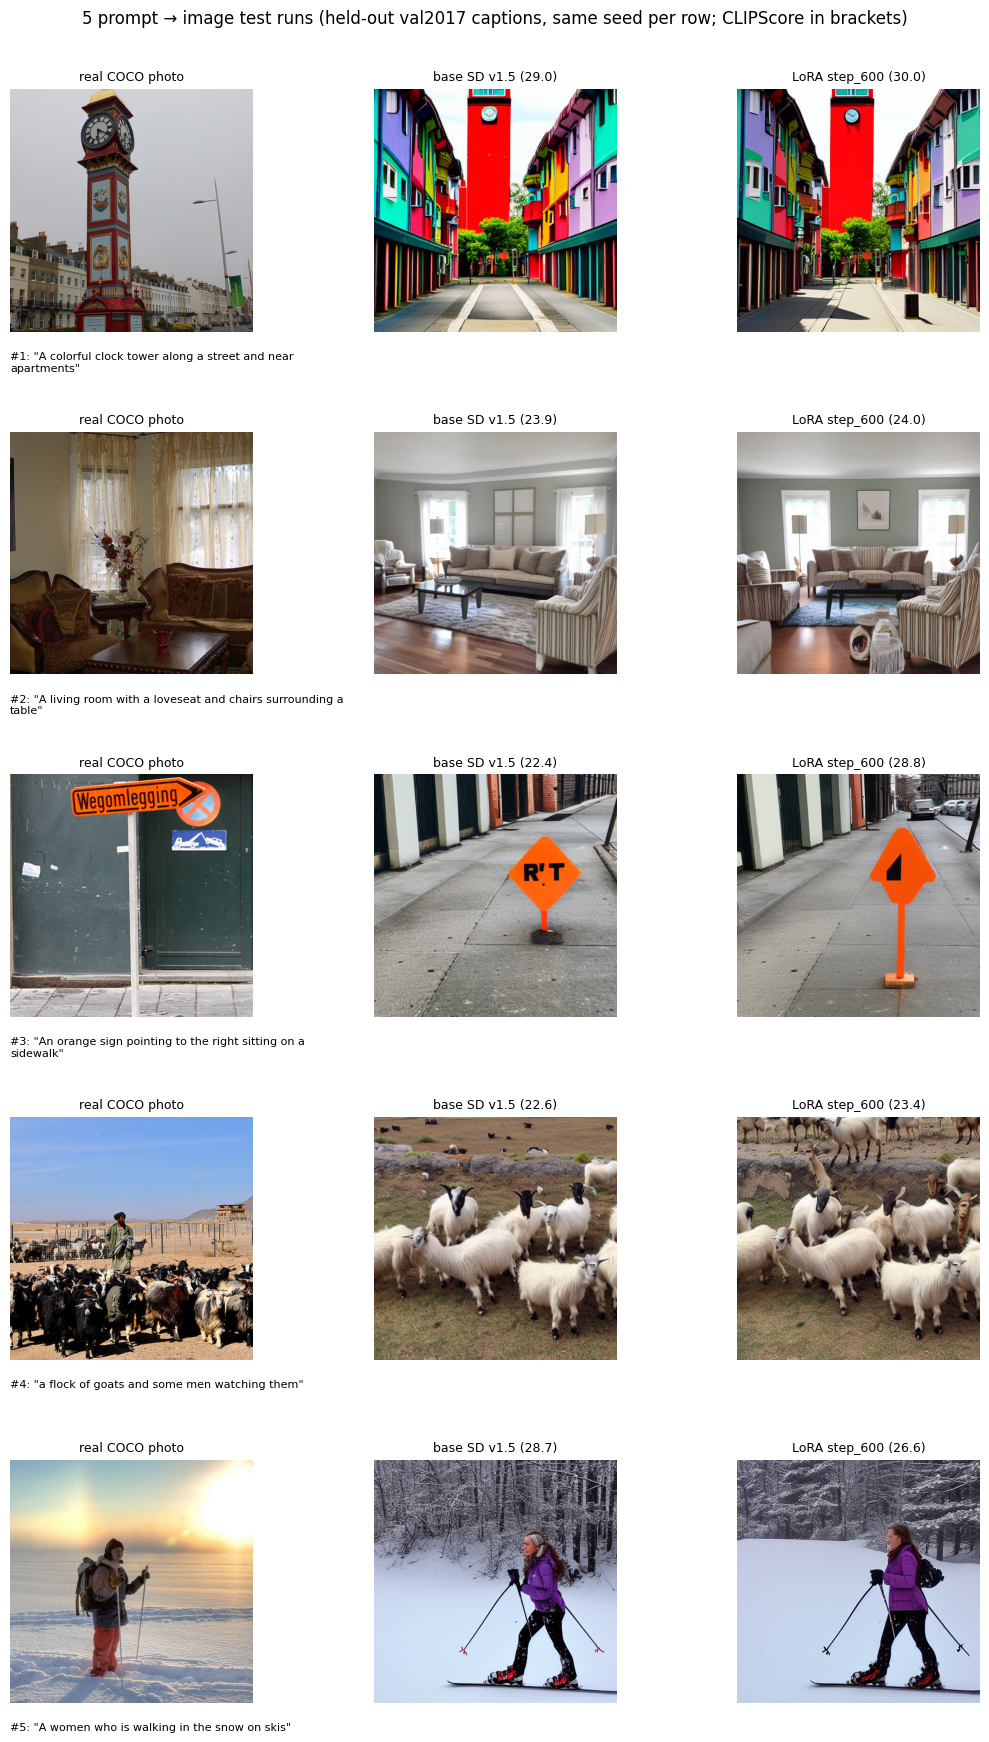

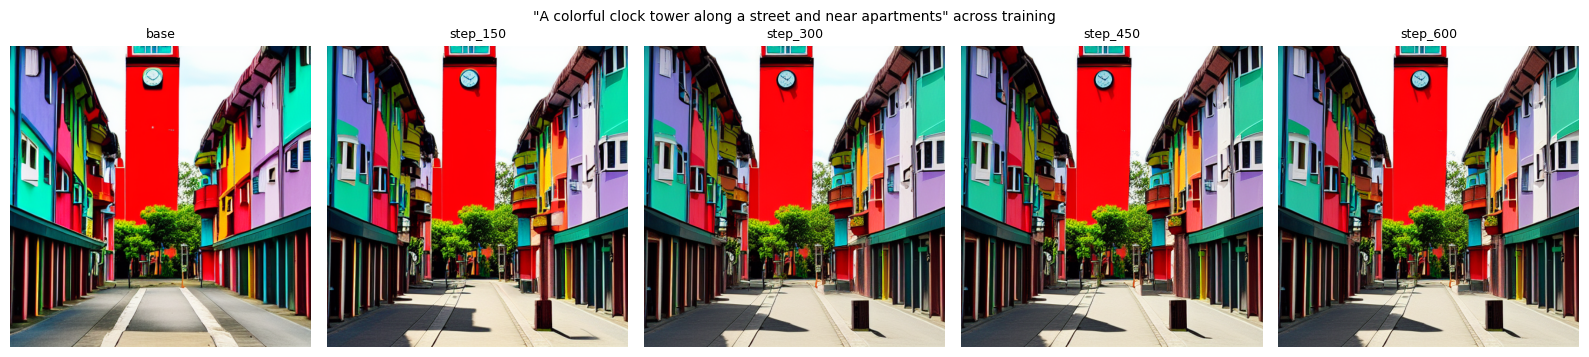

In [ ]:
final = f"step_{max(ckpts)}"
real = [load_square(p) for p in showcase_df.path]
fig, axes = plt.subplots(len(SHOW_PROMPTS), 3, figsize=(10, 3.5 * len(SHOW_PROMPTS)))
fin_cs  = clipscore(show_imgs[final], SHOW_PROMPTS)
base_cs = clipscore(show_imgs["base"], SHOW_PROMPTS)
for k, row in enumerate(axes):
    for a, im, title in zip(row, [real[k], show_imgs["base"][k], show_imgs[final][k]],
                            ["real COCO photo", f"base SD v1.5 ({base_cs[k]:.1f})", f"LoRA {final} ({fin_cs[k]:.1f})"]):
        a.imshow(im); a.axis("off"); a.set_title(title, fontsize=9)
    row[0].text(0, -0.08, "\n".join(textwrap.wrap(f'#{k+1}: "{SHOW_PROMPTS[k]}"', 60)),
                transform=row[0].transAxes, fontsize=8, va="top")
plt.suptitle("5 prompt → image test runs (held-out val2017 captions, same seed per row; CLIPScore in brackets)", y=1.0)
plt.tight_layout(); plt.savefig(RUN/"showcase_grid.png", dpi=150, bbox_inches="tight"); plt.show()

# how one prompt evolves across checkpoints
names = list(models)
fig, ax = plt.subplots(1, len(names), figsize=(3.2 * len(names), 3.6))
for a, n in zip(ax, names):
    a.imshow(show_imgs[n][0]); a.axis("off"); a.set_title(n, fontsize=9)
plt.suptitle(f'"{SHOW_PROMPTS[0]}" across training', fontsize=10)
plt.tight_layout(); plt.savefig(RUN/"checkpoint_progression.png", dpi=150); plt.show()

## 7. Save metrics for the Milestone 2 comparison table

In [ ]:
import diffusers, transformers, peft, platform
best = RESULTS[RESULTS.model != "base"].sort_values("clipscore_mean", ascending=False).iloc[0]
SUMMARY = {
    "run": CFG["run_name"], "method": CFG["method"], "config": CFG,
    **PARAM_INFO, **TRAIN_INFO,
    "val_loss_base": base_val, "val_loss_final": val_log[-1]["val_loss"],
    "clipscore_base": float(RESULTS.loc[RESULTS.model == "base", "clipscore_mean"].iloc[0]),
    "clipscore_final": float(RESULTS.loc[RESULTS.model == final, "clipscore_mean"].iloc[0]),
    "best_checkpoint": best.model,
    "env": {"python": platform.python_version(), "torch": torch.__version__, "diffusers": diffusers.__version__,
            "transformers": transformers.__version__, "peft": peft.__version__, "gpu": torch.cuda.get_device_name(0)},
}
json.dump(SUMMARY, open(RUN/"summary.json", "w"), indent=2, default=str)
print(json.dumps({k: v for k, v in SUMMARY.items() if k not in ("config", "env")}, indent=2, default=str))
print("\nFiles for the report:", *[RUN/f for f in ("showcase_grid.png", "curves.png", "checkpoint_progression.png",
                                                    "eval_results.csv", "summary.json")], sep="\n  ")

{
  "run": "lora_r8_pilot",
  "method": "lora",
  "trainable_params": 1594368,
  "total_unet_params": 861115332,
  "trainable_pct": 0.185,
  "train_minutes": 13.8,
  "sec_per_step": 1.379,
  "peak_gpu_gb": 2.59,
  "images_seen": 2400,
  "val_loss_base": 0.15120280742645265,
  "val_loss_final": 0.15102410569787025,
  "clipscore_base": 25.52,
  "clipscore_final": 26.37,
  "best_checkpoint": "step_600"
}

Files for the report:
  /content/ft_data/runs/lora_r8_pilot/showcase_grid.png
  /content/ft_data/runs/lora_r8_pilot/curves.png
  /content/ft_data/runs/lora_r8_pilot/checkpoint_progression.png
  /content/ft_data/runs/lora_r8_pilot/eval_results.csv
  /content/ft_data/runs/lora_r8_pilot/summary.json


In [20]:
 # Copy this run to Google Drive so it survives the Colab runtime reset
from google.colab import drive; drive.mount("/content/drive")
import shutil; shutil.copytree(RUN, f"/content/drive/MyDrive/generative_project/{CFG['run_name']}", dirs_exist_ok=True)
print("saved to Drive")

Mounted at /content/drive
saved to Drive
